# 异质 NetStim Connection：BrainCell vs NEURON

这个回归例只回答一个问题：相同的 source event、Connection `weight/delay`、ExpSyn 参数和三分支 HH cell，在 BrainCell 与 NEURON 中是否产生相同的膜电位。

两端的随机数算法不必相同。因此先让 BrainCell 的异质 NetStim 实现事件时刻，再在 NEURON 中用单事件 NetStim 精确重放。这样误差只来自 event routing、突触动力学和膜积分。NEURON 内置 `hh` 的速率默认查表插值，这里关闭查表，使两边求值同一组方程（见第 3 节）。

In [1]:
import os
from itertools import combinations

os.environ.setdefault("JAX_PLATFORMS", "cpu")

import brainstate
import brainunit as u
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from neuron import h

import braincell
from braincell import mech
from braincell.filter import AllRegion

brainstate.environ.set(precision=64)
DT_MS = 0.05
DURATION_MS = 8.0

--No graphics will be displayed.


## 1. 相同的 cable 与 HH 参数

每个 cell 含 1 个 soma CV 和两条各 2 个 CV 的 dendrite。10 个 cell 分别代表 5 个 CV 中任取两个位置的 10 种组合；每个 cell 的两个位置各放一个 ExpSyn。

In [2]:
def build_morphology():
    soma = braincell.Branch.from_lengths(
        lengths=[20.0] * u.um, radii=[10.0, 10.0] * u.um, type="soma",
    )
    dend_a = braincell.Branch.from_lengths(
        lengths=[120.0] * u.um, radii=[2.0, 1.0] * u.um, type="basal_dendrite",
    )
    dend_b = braincell.Branch.from_lengths(
        lengths=[160.0] * u.um, radii=[2.5, 0.8] * u.um, type="basal_dendrite",
    )
    morphology = braincell.Morphology.from_root(soma, name="soma")
    morphology.soma.dend_a = dend_a
    morphology.soma.dend_b = dend_b
    return morphology


def build_population(size):
    cell = braincell.Cell(
        build_morphology(), cv_policy=braincell.CVPerBranchList([1, 2, 2]),
        pop_size=(size,), V_init=-65.0 * u.mV, solver="staggered",
    )
    cell.paint(
        AllRegion(),
        mech.CableProperty(
            resting_potential=-65.0 * u.mV,
            membrane_capacitance=1.0 * u.uF / u.cm**2,
            axial_resistivity=100.0 * u.ohm * u.cm,
        ),
        mech.Ion("SodiumFixed", E=50.0 * u.mV),
        mech.Ion("PotassiumFixed", E=-77.0 * u.mV),
        mech.Channel("Na_HH1952", name="na", g_max=120.0 * u.mS / u.cm**2),
        mech.Channel("K_HH1952", name="k", g_max=36.0 * u.mS / u.cm**2),
        mech.Channel("IL", name="leak", g_max=0.3 * u.mS / u.cm**2, E=-54.387 * u.mV),
    )
    return cell

In [3]:
preview = build_population(1)
pair_indices = np.asarray(list(combinations(range(preview.n_cv), 2)), dtype=np.int32)
post = build_population(len(pair_indices))
locations = post.cv_midpoints[pair_indices]

exp = mech.Synapse("ExpSyn", name="compare_exp", tau=2.0 * u.ms, e=0.0 * u.mV)
post.place(locations, exp)
targets = post.synapses[exp]
tau_ms = np.linspace(1.0, 4.0, len(targets))
e_mv = np.linspace(-20.0, 10.0, len(targets))
post.soma.record("v_soma", braincell.observe.state("V"))

assert pair_indices.shape == (10, 2)
assert len(targets) == 20
pd.DataFrame({
    "cell": targets.population_index,
    "branch": [item.branch_id for item in targets.instances],
    "branch_x": [item.branch_x for item in targets.instances],
    "tau (ms)": tau_ms,
    "e (mV)": e_mv,
}).head(8)

,cell,branch,branch_x,tau (ms),e (mV)
0,0,0,0.50,1.000000,-20.000000
1,0,1,0.25,1.157895,-18.421053
2,1,0,0.50,1.315789,-16.842105
3,1,1,0.75,1.473684,-15.263158
4,2,0,0.50,1.631579,-13.684211
5,2,2,0.25,1.789474,-12.105263
6,3,0,0.50,1.947368,-10.526316
7,3,2,0.75,2.105263,-8.947368


## 2. BrainCell：异质 source 与 Connection rows

20 个 NetStim 的 `start/interval/noise` 均可逐 source 设置；20 行 Connection 的 `weight/delay` 也逐行设置。Network 同时拥有 source 和 target，因而一次 `run()` 会统一推进事件源、突触和 cell。

逐 Synapse 的 `tau/e` 是 runtime 参数：`SynapseView.set()` 只修改已初始化的 runtime，所以下面先显式调用 `init_state()` 再设置。初始化后，之前选取的 Synapse 与 Connection 视图失效，要重新选取。

In [4]:
sources = braincell.NetStim(
    size=20,
    start=(1.0 + 0.05 * (np.arange(20) % 5)) * u.ms,
    number=2,
    interval=(3.0 + 0.1 * np.arange(20)) * u.ms,
    noise=np.linspace(0.0, 0.5, 20),
    seed=11,
    name="heterogeneous_netstim",
)
weights_us = np.linspace(0.015, 0.045, 20)
delays_ms = 0.05 * (np.arange(20) % 4)

network = braincell.Network("netstim_neuron_compare", seed=7)
stim_pop = network.add_population("stim", sources)
post_pop = network.add_population("post", post)
connections = network.connect(
    "netstim_to_exp", source=stim_pop, synapse=post_pop.synapses["compare_exp"],
    weight=weights_us * u.uS, delay=delays_ms * u.ms,
)

assert len(connections) == 20
print(network)
pd.DataFrame({
    "source": connections.source_index,
    "target cell": connections.synapse.population_index,
    "weight (uS)": connections.weight.to_decimal(u.uS),
    "delay (ms)": connections.delay.to_decimal(u.ms),
}).head(8)

Network(name='netstim_neuron_compare', populations=2, connections=1, rows=20)
  populations:
    stim: size=20, kind=netstim, model=NetStim, initialized=False
    post: size=10, kind=cell, model=Cell, initialized=False
  connections:
    post: connections=1, rows=20
      netstim_to_exp: NetStim(heterogeneous_netstim) -> ExpSyn(compare_exp), rows=20


,source,target cell,weight (uS),delay (ms)
0,0,0,0.015000,0.00
1,1,0,0.016579,0.05
2,2,1,0.018158,0.10
3,3,1,0.019737,0.15
4,4,2,0.021316,0.00
5,5,2,0.022895,0.05
6,6,3,0.024474,0.10
7,7,3,0.026053,0.15


In [5]:
network.init_state()
targets = post.synapses["compare_exp"]
targets.set(tau=tau_ms * u.ms, e=e_mv * u.mV)
connections = post.connections
assert np.array_equal(connections.source_index, np.arange(20))

braincell_result = network.run(dt=DT_MS * u.ms, duration=DURATION_MS * u.ms)
braincell_block = braincell_result.samples["post"]["v_soma"]
braincell_time_ms = np.asarray(braincell_block.time.to_decimal(u.ms), dtype=float)
braincell_voltage_mv = np.asarray(braincell_block.values.to_decimal(u.mV), dtype=float)
braincell_event_times_ms = np.asarray(sources.event_times.to_decimal(u.ms), dtype=float)

event_rows = []
for row in range(len(connections)):
    source_id = int(connections.source_index[row])
    for event_id in range(int(sources.number[source_id])):
        source_time = float(braincell_event_times_ms[source_id, event_id])
        event_rows.append({
            "source": source_id, "event": event_id,
            "source time (ms)": source_time,
            "arrival time (ms)": source_time + delays_ms[row],
        })

assert braincell_voltage_mv.shape == (160, 10)
print("realized events =", len(event_rows))
pd.DataFrame(event_rows).head(10)

realized events = 40


,source,event,source time (ms),arrival time (ms)
0,0,0,1.000000,1.000000
1,0,1,4.000000,4.000000
2,1,0,1.055624,1.105624
3,1,1,4.115814,4.165814
4,2,0,1.112061,1.212061
5,2,1,4.194294,4.294294
6,3,0,1.373435,1.523435
7,3,1,4.476672,4.626672
8,4,0,1.703073,1.703073
9,4,1,5.563134,5.563134


## 3. NEURON：重建同一模型并重放事件

每个 BrainCell event 在 NEURON 中对应一个 `number=1, noise=0` 的 NetStim。NetCon 使用相同行的 weight 和 delay。两边都包含 `t=0` 初始状态；NEURON 还包含终点 `t=8 ms`，所以最终只裁掉 NEURON 的最后一行。

NEURON 内置的 `hh` 在 `rates` 中用 `TABLE` 把速率按 -100 到 100 mV 的 200 段线性插值，BrainCell 精确求值。保留查表时，静息漂移从第 2 步（0.1 ms）起分歧，事件到来前已到 2.3e-5 mV，经动作电位放大到 0.165 mV（cell 0，2.35 ms）。所以这里设 `h.usetable_hh = 0`，与 `channel_no_conc` 对照中的做法相同；结束后恢复原值。两边的事件在同一步投递（本例没有恰在半步上的到达时刻），ExpSyn 的 `g` 逐点一致。

In [6]:
def make_neuron_section(name, *, length, proximal_diameter, distal_diameter, nseg):
    section = h.Section(name=name)
    section.nseg = nseg
    section.Ra = 100.0
    section.cm = 1.0
    h.pt3dclear(sec=section)
    h.pt3dadd(0.0, 0.0, 0.0, proximal_diameter, sec=section)
    h.pt3dadd(length, 0.0, 0.0, distal_diameter, sec=section)
    section.insert("hh")
    section.ena = 50.0
    section.ek = -77.0
    for segment in section:
        segment.hh.gnabar = 0.120
        segment.hh.gkbar = 0.036
        segment.hh.gl = 0.0003
        segment.hh.el = -54.387
    return section


def run_neuron_replay():
    h.load_file("stdrun.hoc")
    previous_celsius = float(h.celsius)
    previous_usetable = float(h.usetable_hh)
    h.celsius = 6.3
    # The built-in hh interpolates its rates in a TABLE; BrainCell evaluates them exactly.
    h.usetable_hh = 0
    cells, sections, synapses = [], [], []
    replay_stims, replay_netcons, voltage_vectors = [], [], []
    try:
        for cell_id in range(10):
            soma = make_neuron_section(
                f"compare_soma_{cell_id}", length=20.0,
                proximal_diameter=20.0, distal_diameter=20.0, nseg=1,
            )
            dend_a = make_neuron_section(
                f"compare_dend_a_{cell_id}", length=120.0,
                proximal_diameter=4.0, distal_diameter=2.0, nseg=2,
            )
            dend_b = make_neuron_section(
                f"compare_dend_b_{cell_id}", length=160.0,
                proximal_diameter=5.0, distal_diameter=1.6, nseg=2,
            )
            dend_a.connect(soma(1.0), 0.0)
            dend_b.connect(soma(1.0), 0.0)
            cell_sections = {0: soma, 1: dend_a, 2: dend_b}
            cells.append(cell_sections)
            sections.extend(cell_sections.values())
            voltage_vectors.append(h.Vector().record(soma(0.5)._ref_v))

        for target_id, instance in enumerate(targets.instances):
            syn = h.ExpSyn(cells[instance.population_index][instance.branch_id](instance.branch_x))
            syn.tau = tau_ms[target_id]
            syn.e = e_mv[target_id]
            synapses.append(syn)

        for row in range(len(connections)):
            source_id = int(connections.source_index[row])
            target_id = int(connections.target_index[row])
            for event_id in range(int(sources.number[source_id])):
                stim = h.NetStim()
                stim.start = float(braincell_event_times_ms[source_id, event_id])
                stim.number = 1
                stim.interval = 1.0
                stim.noise = 0.0
                netcon = h.NetCon(stim, synapses[target_id])
                netcon.weight[0] = weights_us[row]
                netcon.delay = delays_ms[row]
                replay_stims.append(stim)
                replay_netcons.append(netcon)

        time_vector = h.Vector().record(h._ref_t)
        h.cvode_active(0)
        h.dt = DT_MS
        h.steps_per_ms = 1.0 / DT_MS
        h.secondorder = 0
        h.finitialize(-65.0)
        h.tstop = DURATION_MS
        h.run()
        return (
            np.asarray(time_vector, dtype=float),
            np.column_stack([np.asarray(vector, dtype=float) for vector in voltage_vectors]),
            len(replay_stims),
        )
    finally:
        h.celsius = previous_celsius
        h.usetable_hh = previous_usetable
        for section in sections:
            h.delete_section(sec=section)

## 4. 对齐与误差

裁掉 NEURON 的终点行后，两边都是 `(160 time steps, 10 cells)`。下面同时检查时间轴、逐点电压和每个 cell 峰值所在的时间步。

In [7]:
neuron_time_full_ms, neuron_voltage_full_mv, replay_count = run_neuron_replay()
neuron_time_ms = neuron_time_full_ms[:-1]
neuron_voltage_mv = neuron_voltage_full_mv[:-1]
physical_braincell_time_ms = braincell_time_ms

assert neuron_voltage_full_mv.shape == (161, 10)
assert neuron_voltage_mv.shape == braincell_voltage_mv.shape
np.testing.assert_allclose(neuron_time_ms, physical_braincell_time_ms, atol=1e-5, rtol=0.0)

error_mv = braincell_voltage_mv - neuron_voltage_mv
summary = pd.DataFrame([{
    "replayed events": replay_count,
    "MAE (mV)": np.mean(np.abs(error_mv)),
    "RMSE (mV)": np.sqrt(np.mean(error_mv**2)),
    "max abs (mV)": np.max(np.abs(error_mv)),
}])
display(summary)

np.testing.assert_allclose(braincell_voltage_mv, neuron_voltage_mv, atol=1e-5, rtol=0.0)
np.testing.assert_array_equal(
    np.argmax(braincell_voltage_mv, axis=0),
    np.argmax(neuron_voltage_mv, axis=0),
)

,replayed events,MAE (mV),RMSE (mV),max abs (mV)
0,40,1.632794e-08,3.318582e-08,2.841691e-07


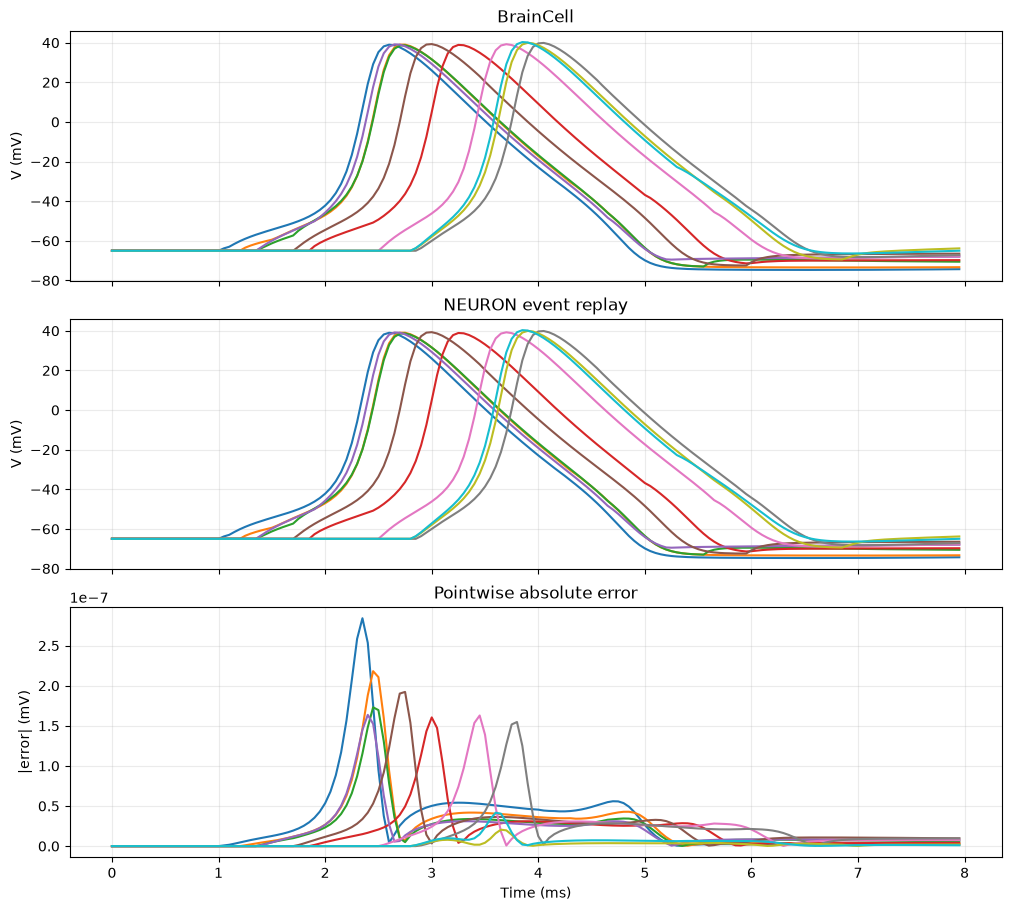

In [8]:
colors = plt.cm.tab10(np.arange(10))
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True, constrained_layout=True)
for cell_id, color in enumerate(colors):
    axes[0].plot(physical_braincell_time_ms, braincell_voltage_mv[:, cell_id], color=color)
    axes[1].plot(neuron_time_ms, neuron_voltage_mv[:, cell_id], color=color)
    axes[2].plot(physical_braincell_time_ms, np.abs(error_mv[:, cell_id]), color=color)
axes[0].set(title="BrainCell", ylabel="V (mV)")
axes[1].set(title="NEURON event replay", ylabel="V (mV)")
axes[2].set(title="Pointwise absolute error", ylabel="|error| (mV)", xlabel="Time (ms)")
for axis in axes:
    axis.grid(alpha=0.25)
plt.show()

## 结论

这个对比覆盖了异质 NetStim 参数、一对一 Connection rows、逐行 weight/delay、逐 Synapse tau/e、分支位置映射以及 fixed-step staggered 更新。NEURON 侧关闭 `hh` 的速率查表后，最大误差在 `atol=1e-5` mV 之内。随机 NetStim 本身的统计分布应另做统计测试；这里用事件重放隔离了跨平台 RNG 差异。